# Классификация грибов (ResNet18)

## Через Google Colab (T4)

In [16]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Конфиг и импорты

In [15]:
import os, json, time, random, shutil, warnings
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Subset, WeightedRandomSampler
from torchvision import datasets, transforms, models
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from tqdm.auto import tqdm

import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageFile

ImageFile.LOAD_TRUNCATED_IMAGES = True
warnings.filterwarnings("ignore")

# ---------------- CONFIG ----------------
DATASET_ROOT   = Path('/content/drive/MyDrive/Colab Notebooks/Mushrooms')
LOCAL_DATASET  = Path('/content/Mushrooms_local')
CHECKPOINT_DIR = Path('/content/drive/MyDrive/Colab Notebooks/Mushrooms_checkpoints')
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

LAST_PATH    = CHECKPOINT_DIR / 'last.pt'
BEST_PATH    = CHECKPOINT_DIR / 'best.pt'
HISTORY_PATH = CHECKPOINT_DIR / 'history.json'

EPOCHS       = 30
BATCH_SIZE   = 64
LR           = 1e-3
WEIGHT_DECAY = 1e-4
IMG_SIZE     = 160
NUM_WORKERS  = 0
SEED         = 42
TRAIN_RATIO  = 6/7

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.backends.cudnn.benchmark = True

print("Device:", DEVICE)

def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

set_seed(SEED)

Device: cuda


## Локальная копия датасета (для ускорения эпох)

In [17]:
FORCE_COPY = False   # True - скопировать в любом случае

if FORCE_COPY and LOCAL_DATASET.exists():
    shutil.rmtree(LOCAL_DATASET)

if not LOCAL_DATASET.exists():
    print(f"{DATASET_ROOT} -> {LOCAL_DATASET} загрузка...")
    t0 = time.time()
    shutil.copytree(DATASET_ROOT, LOCAL_DATASET)
    print(f"Готово за {time.time()-t0:.1f}s")
else:
    print("Локальная копия уже есть, использую её.")

DATA_SOURCE = LOCAL_DATASET
print(f"Источник данных: {DATA_SOURCE}")

Локальная копия уже есть, использую её.
Источник данных: /content/Mushrooms_local


## Трансформации (упрощённые для ускорения)


In [18]:
train_tf = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.6, 1.0), ratio=(0.6, 1.8)),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.15),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225]),
])

val_tf = transforms.Compose([
    transforms.Resize(int(IMG_SIZE * 1.14)),
    transforms.CenterCrop(IMG_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225]),
])

## Загрузка датасета и split 6:1

In [19]:
train_full = datasets.ImageFolder(root=str(DATA_SOURCE), transform=train_tf)
val_full   = datasets.ImageFolder(root=str(DATA_SOURCE), transform=val_tf)

class_names = train_full.classes
num_classes = len(class_names)
print(f"Classes ({num_classes}): {class_names}")
print(f"Total images: {len(train_full)}")

def stratified_split_indices(dataset, train_ratio, seed=42):
    rng = random.Random(seed)
    by_class = {}
    for idx, (_, lbl) in enumerate(dataset.samples):
        by_class.setdefault(lbl, []).append(idx)
    train_idx, val_idx = [], []
    for lbl, idxs in by_class.items():
        idxs = idxs[:]
        rng.shuffle(idxs)
        n = len(idxs)
        n_train = max(1, min(int(round(n * train_ratio)), n - 1))
        train_idx.extend(idxs[:n_train])
        val_idx.extend(idxs[n_train:])
    return train_idx, val_idx

train_idx, val_idx = stratified_split_indices(train_full, TRAIN_RATIO, SEED)
print(f"Train: {len(train_idx)} | Val (held-out 1/7): {len(val_idx)}")

def per_class_counts(dataset, idxs):
    c = {n: 0 for n in class_names}
    for i in idxs:
        c[class_names[dataset.samples[i][1]]] += 1
    return c

print("\nTrain per class:", per_class_counts(train_full, train_idx))
print("Val per class:  ", per_class_counts(val_full,   val_idx))

Classes (9): ['Agaricus', 'Amanita', 'Boletus', 'Cortinarius', 'Entoloma', 'Hygrocybe', 'Lactarius', 'Russula', 'Suillus']
Total images: 6714
Train: 5757 | Val (held-out 1/7): 957

Train per class: {'Agaricus': 303, 'Amanita': 643, 'Boletus': 920, 'Cortinarius': 717, 'Entoloma': 312, 'Hygrocybe': 271, 'Lactarius': 1340, 'Russula': 984, 'Suillus': 267}
Val per class:   {'Agaricus': 50, 'Amanita': 107, 'Boletus': 153, 'Cortinarius': 119, 'Entoloma': 52, 'Hygrocybe': 45, 'Lactarius': 223, 'Russula': 164, 'Suillus': 44}


## DataLoader + Компенсация дисбаланса

In [20]:
def make_weighted_sampler(dataset, indices):
    labels = [dataset.samples[i][1] for i in indices]
    counts = np.bincount(labels, minlength=len(dataset.classes)).astype(np.float32)
    class_w = 1.0 / np.maximum(counts, 1.0)
    sample_w = [float(class_w[l]) for l in labels]
    return WeightedRandomSampler(sample_w, num_samples=len(indices), replacement=True)

train_subset = Subset(train_full, train_idx)
val_subset   = Subset(val_full,   val_idx)

train_loader = DataLoader(
    train_subset, batch_size=BATCH_SIZE,
    sampler=make_weighted_sampler(train_full, train_idx),
    num_workers=NUM_WORKERS, pin_memory=True, drop_last=False,
    persistent_workers=(NUM_WORKERS > 0),
)
val_loader = DataLoader(
    val_subset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=True,
    persistent_workers=(NUM_WORKERS > 0),
)
print(f"train batches: {len(train_loader)} | val batches: {len(val_loader)}")

train batches: 90 | val batches: 15


## Модель: ResNet18 (11M параметров)

In [21]:
def build_model(num_classes, device):
    m = models.resnet18(weights=None)   # from scratch
    m.fc = nn.Linear(m.fc.in_features, num_classes)
    return m.to(device)

model     = build_model(num_classes, DEVICE)
criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

print(f"Params: {sum(p.numel() for p in model.parameters())/1e6:.2f}M")

Params: 11.18M


## Сохранение чекпоинтов


In [22]:
def save_checkpoint(path, epoch, best_acc, history):
    torch.save({
        'model':     model.state_dict(),
        'optimizer': optimizer.state_dict(),
        'scheduler': scheduler.state_dict(),
        'epoch':     epoch,
        'best_acc':  best_acc,
        'history':   history,
        'classes':   class_names,
    }, path)

def load_checkpoint_into(path):
    ckpt = torch.load(path, map_location=DEVICE)
    model.load_state_dict(ckpt['model'])
    optimizer.load_state_dict(ckpt['optimizer'])
    scheduler.load_state_dict(ckpt['scheduler'])
    return ckpt

def load_history():
    if HISTORY_PATH.exists():
        with open(HISTORY_PATH) as f:
            return json.load(f)
    return {'train_loss': [], 'train_acc': [],
            'val_loss': [],   'val_acc': [],
            'val_f1': [],     'lr': []}

def dump_history(h):
    with open(HISTORY_PATH, 'w') as f:
        json.dump(h, f, indent=2)

## Функции train/evaluate

In [23]:
def train_one_epoch(loader, epoch, epochs):
    model.train()
    total_loss, correct, total = 0.0, 0, 0
    pbar = tqdm(loader, desc=f"  train [{epoch+1}/{epochs}]",
                leave=False, position=1, dynamic_ncols=True)
    it = iter(pbar)
    try:
        for x, y in it:
            x = x.to(DEVICE, non_blocking=True)
            y = y.to(DEVICE, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            logits = model(x)
            loss   = criterion(logits, y)
            loss.backward()
            optimizer.step()

            total_loss += loss.item() * y.size(0)
            correct    += (logits.argmax(1) == y).sum().item()
            total      += y.size(0)

            pbar.set_postfix(loss=f"{total_loss/total:.4f}",
                             acc=f"{correct/total:.4f}")
    finally:
        try: del it
        except Exception: pass
        pbar.close()
    return total_loss / total, correct / total

@torch.no_grad()
def evaluate(loader, epoch=None, epochs=None):
    model.eval()
    total_loss, total = 0.0, 0
    preds, targets = [], []
    desc = f"  val   [{epoch+1}/{epochs}]" if epoch is not None else "  val"
    pbar = tqdm(loader, desc=desc, leave=False, position=1, dynamic_ncols=True)
    it = iter(pbar)
    try:
        for x, y in it:
            x = x.to(DEVICE); y = y.to(DEVICE)
            logits = model(x)
            loss = criterion(logits, y)
            total_loss += loss.item() * y.size(0)
            total      += y.size(0)
            preds.extend(logits.argmax(1).cpu().tolist())
            targets.extend(y.cpu().tolist())
            pbar.set_postfix(loss=f"{total_loss/total:.4f}")
    finally:
        try: del it
        except Exception: pass
        pbar.close()
    acc = accuracy_score(targets, preds)
    f1  = f1_score(targets, preds, average='macro', zero_division=0)
    return total_loss / total, acc, f1, preds, targets

## Основной цикл обучения
- При остановке чекпоинт сохраняется в last.pt/best.pt
- Повторный запуск - продолжение с сохранения

In [24]:
start_epoch = 0
best_acc    = 0.0
history     = load_history()

if LAST_PATH.exists():
    ckpt = load_checkpoint_into(LAST_PATH)
    start_epoch = ckpt['epoch'] + 1
    best_acc    = float(ckpt.get('best_acc', 0.0))
    history     = ckpt.get('history', history)
    print(f"Resumed from epoch {start_epoch} (prev best_acc={best_acc:.4f})")
else:
    print("Training from scratch")

last_saved_epoch = start_epoch - 1
stop_reason = None

epochs_bar = tqdm(total=EPOCHS, initial=start_epoch,
                  desc="Epochs", position=0, dynamic_ncols=True)
epochs_bar.set_postfix(best=f"{best_acc:.4f}")

try:
    for epoch in range(start_epoch, EPOCHS):
        t0 = time.time()

        tr_loss, tr_acc = train_one_epoch(train_loader, epoch, EPOCHS)
        va_loss, va_acc, va_f1, _, _ = evaluate(val_loader, epoch, EPOCHS)
        scheduler.step()
        lr_now = optimizer.param_groups[0]['lr']

        history['train_loss'].append(tr_loss)
        history['train_acc'].append(tr_acc)
        history['val_loss'].append(va_loss)
        history['val_acc'].append(va_acc)
        history['val_f1'].append(va_f1)
        history['lr'].append(lr_now)

        if va_acc > best_acc:
            best_acc = va_acc
            save_checkpoint(BEST_PATH, epoch, best_acc, history)

        save_checkpoint(LAST_PATH, epoch, best_acc, history)
        dump_history(history)
        last_saved_epoch = epoch

        dt = time.time() - t0
        tqdm.write(
            f"[{epoch+1:02d}/{EPOCHS}] {dt:6.1f}s  "
            f"tr_loss={tr_loss:.4f} tr_acc={tr_acc:.4f} | "
            f"val_loss={va_loss:.4f} val_acc={va_acc:.4f} val_F1={va_f1:.4f} "
            f"lr={lr_now:.2e}  best={best_acc:.4f}"
        )

        epochs_bar.update(1)
        epochs_bar.set_postfix(
            tr_loss=f"{tr_loss:.3f}", tr_acc=f"{tr_acc:.3f}",
            val_loss=f"{va_loss:.3f}", val_acc=f"{va_acc:.3f}",
            val_f1=f"{va_f1:.3f}", best=f"{best_acc:.3f}",
            lr=f"{lr_now:.1e}",
        )

except KeyboardInterrupt:
    stop_reason = 'keyboard_interrupt'
    tqdm.write("\nKeyboardInterrupt — saving...")
finally:
    epochs_bar.close()
    save_checkpoint(LAST_PATH, last_saved_epoch, best_acc, history)
    dump_history(history)
    if stop_reason:
        print(f"STOP ({stop_reason}). Last completed epoch: {last_saved_epoch+1}")
        print(f"To resume: re-run this cell -> will start from epoch {last_saved_epoch+2}")

print(f"Best val accuracy: {best_acc:.4f}")

Training from scratch


Epochs:   0%|          | 0/30 [00:00<?, ?it/s]

  train [1/30]:   0%|          | 0/90 [00:00<?, ?it/s]

  val   [1/30]:   0%|          | 0/15 [00:00<?, ?it/s]

[01/30]   75.4s  tr_loss=2.0004 tr_acc=0.2699 | val_loss=2.0972 val_acc=0.2915 val_F1=0.2159 lr=9.97e-04  best=0.2915


  train [2/30]:   0%|          | 0/90 [00:00<?, ?it/s]

... (82 outputs left out)

[29/30]   71.4s  tr_loss=0.2856 tr_acc=0.9083 | val_loss=1.0125 val_acc=0.6917 val_F1=0.6603 lr=2.74e-06  best=0.6917


  train [30/30]:   0%|          | 0/90 [00:00<?, ?it/s]

  val   [30/30]:   0%|          | 0/15 [00:00<?, ?it/s]

[30/30]   70.3s  tr_loss=0.2920 tr_acc=0.9039 | val_loss=1.0071 val_acc=0.6876 val_F1=0.6566 lr=0.00e+00  best=0.6917
Best val accuracy: 0.6917


## Графики кривых обучения

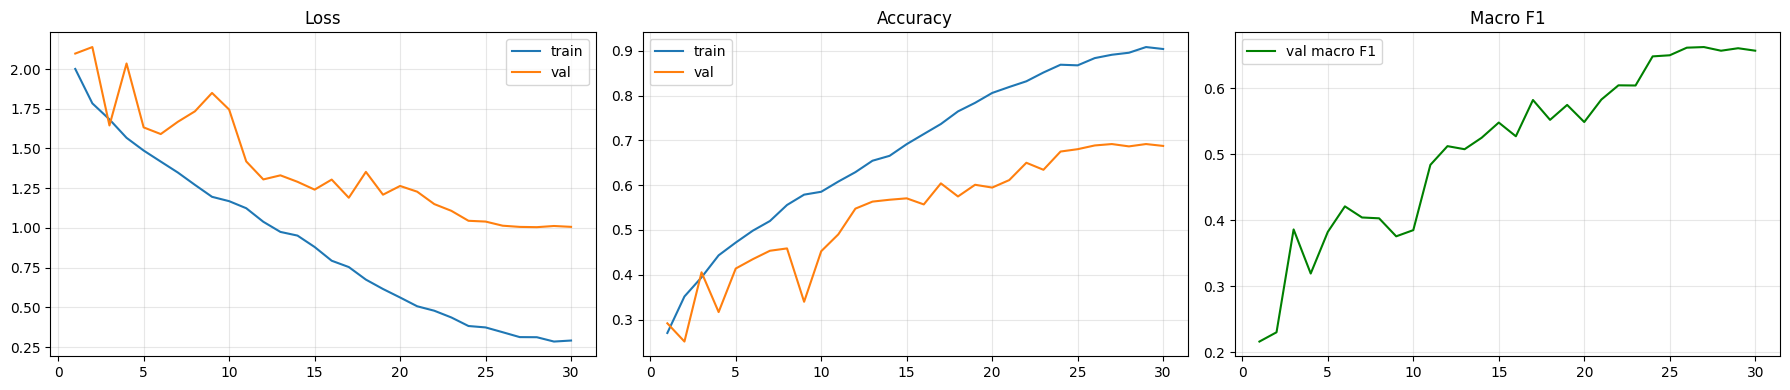

In [25]:
def plot_history(history):
    if not history['train_loss']:
        print("History пустой"); return
    ep = range(1, len(history['train_loss']) + 1)
    fig, ax = plt.subplots(1, 3, figsize=(18, 4))
    ax[0].plot(ep, history['train_loss'], label='train')
    ax[0].plot(ep, history['val_loss'],   label='val')
    ax[0].set_title('Loss'); ax[0].legend(); ax[0].grid(alpha=.3)

    ax[1].plot(ep, history['train_acc'], label='train')
    ax[1].plot(ep, history['val_acc'],   label='val')
    ax[1].set_title('Accuracy'); ax[1].legend(); ax[1].grid(alpha=.3)

    ax[2].plot(ep, history['val_f1'], color='green', label='val macro F1')
    ax[2].set_title('Macro F1'); ax[2].legend(); ax[2].grid(alpha=.3)
    plt.tight_layout(); plt.show()

if 'history' not in globals() or not history.get('train_loss'):
    history = load_history()
plot_history(history)

## Общие метрики, Confusion Matrix

Evaluating from best.pt: epoch 27, val_acc=0.6917


  val:   0%|          | 0/15 [00:00<?, ?it/s]


Held-out (1/7) evaluation:
  Accuracy : 0.6917
  Macro F1 : 0.6621
  Loss     : 1.0068

Classification report:
              precision    recall  f1-score   support

    Agaricus     0.4706    0.6400    0.5424        50
     Amanita     0.7238    0.7103    0.7170       107
     Boletus     0.8387    0.8497    0.8442       153
 Cortinarius     0.6838    0.6723    0.6780       119
    Entoloma     0.5645    0.6731    0.6140        52
   Hygrocybe     0.7273    0.7111    0.7191        45
   Lactarius     0.7020    0.6233    0.6603       223
     Russula     0.7066    0.7195    0.7130       164
     Suillus     0.4878    0.4545    0.4706        44

    accuracy                         0.6917       957
   macro avg     0.6561    0.6726    0.6621       957
weighted avg     0.6966    0.6917    0.6926       957



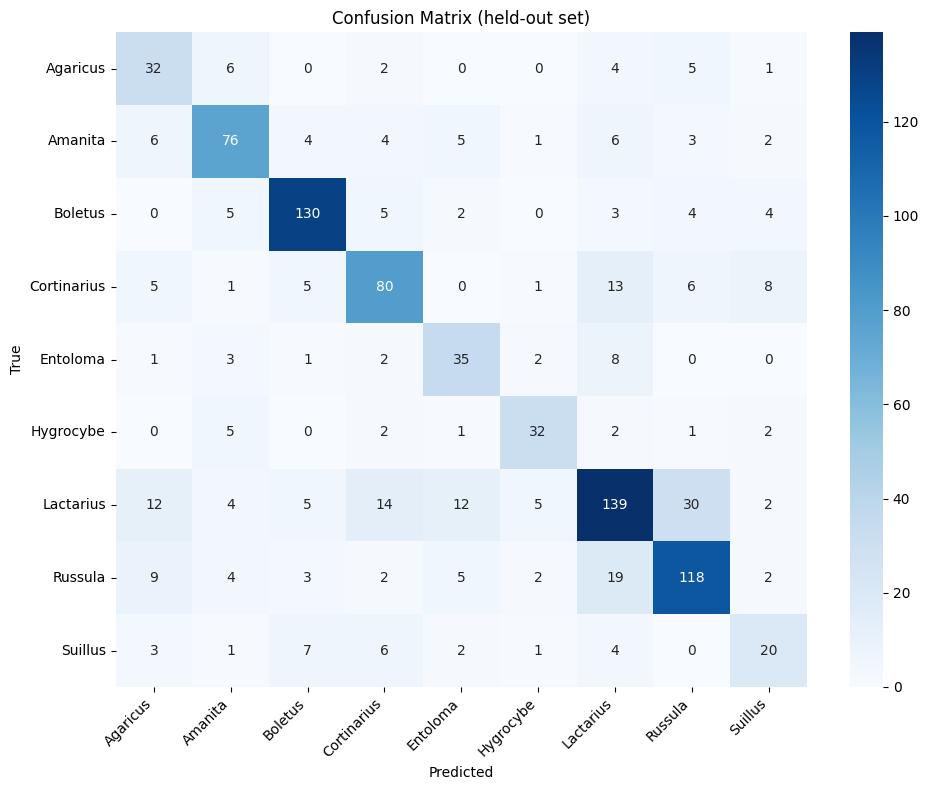

In [26]:
if BEST_PATH.exists():
    ckpt_path, tag = BEST_PATH, 'best.pt'
elif LAST_PATH.exists():
    ckpt_path, tag = LAST_PATH, 'last.pt (best.pt не создан)'
else:
    raise FileNotFoundError("Нет ни best.pt, ни last.pt — нечего оценивать.")

ckpt = load_checkpoint_into(ckpt_path)
print(f"Evaluating from {tag}: epoch {ckpt['epoch']+1}, val_acc={ckpt['best_acc']:.4f}")

va_loss, va_acc, va_f1, preds, targets = evaluate(val_loader)
print(f"\nHeld-out (1/7) evaluation:")
print(f"  Accuracy : {va_acc:.4f}")
print(f"  Macro F1 : {va_f1:.4f}")
print(f"  Loss     : {va_loss:.4f}")

print("\nClassification report:")
print(classification_report(targets, preds, target_names=class_names, digits=4))

cm = confusion_matrix(targets, preds)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted'); plt.ylabel('True')
plt.title('Confusion Matrix (held-out set)')
plt.xticks(rotation=45, ha='right'); plt.yticks(rotation=0)
plt.tight_layout(); plt.show()

## Summary
На основе полученных результатов можно сделать вывод, что модель неплохо научилась отличать грибы, хоть и заметно, что присутствует недообучение. Выбор более сложной модели и/или увеличение числа эпох наверняка бы улучшили имеющийся результат. К сожалению бесплатные ресурсы Google Colab ограничены, поэтому я остановился на этом.